## Khởi tạo môi trường, import thư viện và thiết lập dữ liệu

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

import subprocess
import sys
from pathlib import Path

# Tự động cài đặt gdown để tải dữ liệu trực tiếp từ Drive
try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

HO_TEN = "Nguyễn Anh Nguyên"
MSSV = "6451071053"

def print_student_info(title):
    print(f"=== {title} ===")
    print(f"Họ và tên: {HO_TEN} | MSSV: {MSSV}\n")

# Tên cột chuẩn theo đề bài
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

TRAIN_DRIVE_ID = "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB"
TEST_DRIVE_ID = "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD"

train_file = Path("adult.data.csv")
test_file = Path("adult.test.csv")

# Tải 2 file từ Google Drive nếu máy ảo chưa có
if not train_file.is_file():
    gdown.download(id=TRAIN_DRIVE_ID, output=str(train_file), quiet=False, fuzzy=True)

if not test_file.is_file():
    gdown.download(id=TEST_DRIVE_ID, output=str(test_file), quiet=False, fuzzy=True)

print("Hoàn tất nạp thư viện và tải dữ liệu thành công!")

Hoàn tất nạp thư viện và tải dữ liệu thành công!


## Câu 1: Nhập dữ liệu đầu vào và thống kê số lượng mẫu

In [2]:
print_student_info("CÂU 1: NHẬP DỮ LIỆU ĐẦU VÀO & THỐNG KÊ SỐ LƯỢNG MẪU")

column_names_full = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

# Kiểm tra xem file test có bao nhiêu cột
with open("adult.test.csv", "r", encoding="utf-8") as f:
    # Bỏ qua dòng trống hoặc dòng chú thích đầu
    lines = [line.strip() for line in f if line.strip() and not line.startswith('|')]
    first_data_line = lines[0] if len(lines) > 0 else ""
    num_cols_test = len(first_data_line.split(','))

print(f"Số cột phát hiện trong adult.test.csv: {num_cols_test}")

# Nếu file test đã bị xóa cột fnlwgt (chỉ còn 14 cột)
if num_cols_test == 14:
    cols_test = [c for c in column_names_full if c != 'fnlwgt']
else:
    cols_test = column_names_full

# Đọc file train
with open("adult.data.csv", "r", encoding="utf-8") as f:
    skip_train = 1 if "age" in f.readline().lower() else 0

train_df = pd.read_csv("adult.data.csv", names=column_names_full, skiprows=skip_train, skipinitialspace=True)
test_df = pd.read_csv("adult.test.csv", names=cols_test, skiprows=1, skipinitialspace=True)

print(f"Number of training data: {len(train_df)}")
print(f"Number of test data: {len(test_df)}")

=== CÂU 1: NHẬP DỮ LIỆU ĐẦU VÀO & THỐNG KÊ SỐ LƯỢNG MẪU ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số cột phát hiện trong adult.test.csv: 14
Number of training data: 32561
Number of test data: 16281


## Câu 2: Tiến hành tiền xử lý dữ liệu

In [3]:
print_student_info("CÂU 2: TIỀN XỬ LÝ DỮ LIỆU")

# 1. Bỏ header thừa nếu có
train_df = train_df[train_df['age'].astype(str).str.strip().str.lower() != 'age'].copy()
test_df = test_df[test_df['age'].astype(str).str.strip().str.lower() != 'age'].copy()

# 2. Xóa khoảng trắng thừa ở các cột chuỗi
for col in train_df.columns:
    if train_df[col].dtype == 'object':
        train_df[col] = train_df[col].astype(str).str.strip()
for col in test_df.columns:
    if test_df[col].dtype == 'object':
        test_df[col] = test_df[col].astype(str).str.strip()

# 3. Chuẩn hóa nhãn income
test_df['income'] = test_df['income'].astype(str).str.rstrip('.')

# 4. Thay '?' bằng NaN và dropna
train_df.replace('?', np.nan, inplace=True)
test_df.replace('?', np.nan, inplace=True)
train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# 5. Xóa cột fnlwgt nếu tồn tại
if 'fnlwgt' in train_df.columns:
    train_df.drop('fnlwgt', axis=1, inplace=True)
if 'fnlwgt' in test_df.columns:
    test_df.drop('fnlwgt', axis=1, inplace=True)

# 6. Ép kiểu int64 cho 5 cột số
numeric_columns = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for col in numeric_columns:
    train_df[col] = pd.to_numeric(train_df[col], errors='coerce').astype('int64')
    test_df[col] = pd.to_numeric(test_df[col], errors='coerce').astype('int64')

train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

print("Số lượng dữ liệu huấn luyện và kiểm thử là")
print(f"    Number of training data: {train_df.shape[0]}")
print(f"    Number of test data: {test_df.shape[0]}\n")

# 7. Nối hai tập dữ liệu vào biến 'data'
data = pd.concat([train_df, test_df], axis=0, ignore_index=True)
print("Sau khi tiền xử lý nối hai phần dữ liệu vào biến data sẽ nhận được khối dữ liệu có thông tin như sau\n")
data.info()

=== CÂU 2: TIỀN XỬ LÝ DỮ LIỆU ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Số lượng dữ liệu huấn luyện và kiểm thử là
    Number of training data: 30162
    Number of test data: 15060

Sau khi tiền xử lý nối hai phần dữ liệu vào biến data sẽ nhận được khối dữ liệu có thông tin như sau

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  452

## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

=== CÂU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053



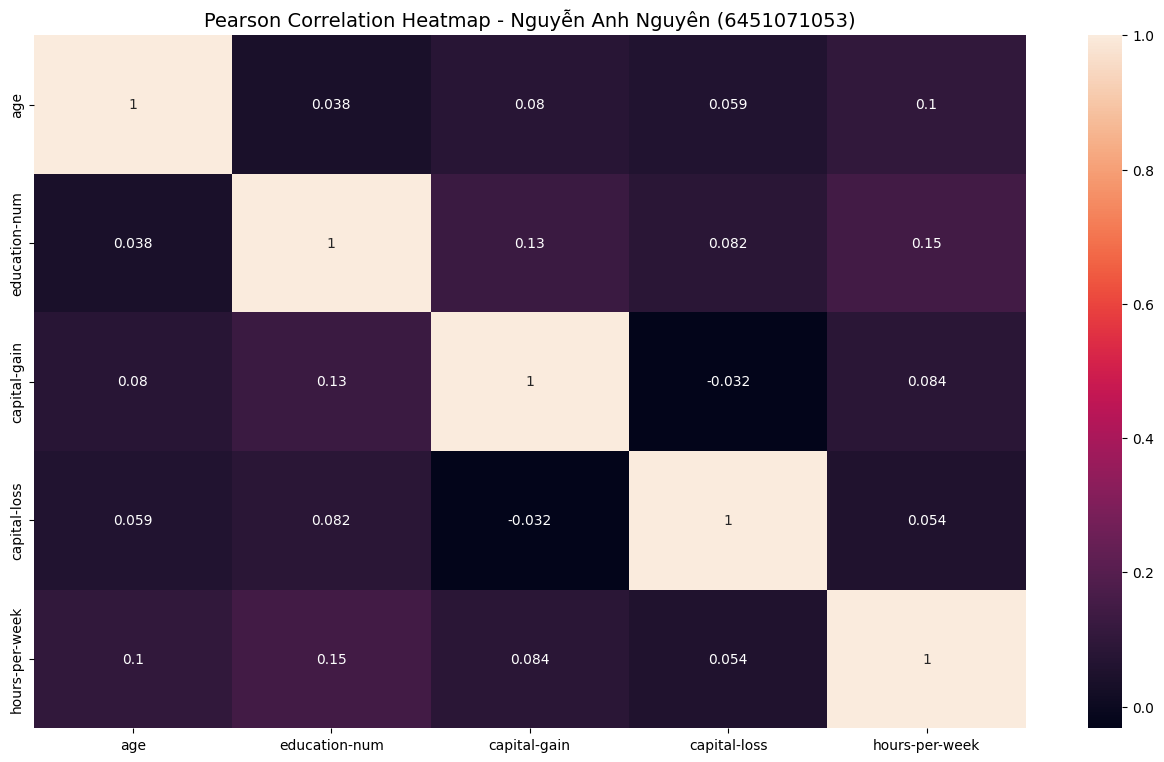

Nhận xét: Trong đồ thị này, màu càng đậm chứng tỏ mức độ tương đồng càng thấp.
Nhận thấy, không có thuộc tính nào tương đồng cao với nhau nên không cần thiết phải loại bỏ cột nào.


In [4]:
print_student_info("CÂU 3: KHẢO SÁT ĐỘ TƯƠNG ĐỒNG PEARSON")

# Lấy ma trận tương quan giữa các cột số
corr_matrix = data.select_dtypes(include=[np.number]).corr(method='pearson')

# Biểu diễn đồ thị seaborn heatmap theo đúng hướng dẫn
plt.figure(figsize=(16, 9))
sns.heatmap(corr_matrix, annot=True)
plt.title(f"Pearson Correlation Heatmap - {HO_TEN} ({MSSV})", fontsize=14)
plt.show()

print("Nhận xét: Trong đồ thị này, màu càng đậm chứng tỏ mức độ tương đồng càng thấp.")
print("Nhận thấy, không có thuộc tính nào tương đồng cao với nhau nên không cần thiết phải loại bỏ cột nào.")

## Câu 4: Tách các cột dữ liệu thành hai phần (features và labels)

In [5]:
print_student_info("CÂU 4: TÁCH FEATURES VÀ LABELS")

# Tách các cột dữ liệu theo đúng cú pháp hướng dẫn
features = data.drop('income', axis=1)
labels = data['income']

print("Đã tách thành công features và labels:")
print("- Số lượng cột features:", features.shape[1])
print("- Kích thước labels:", labels.shape)

=== CÂU 4: TÁCH FEATURES VÀ LABELS ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Đã tách thành công features và labels:
- Số lượng cột features: 13
- Kích thước labels: (45222,)


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [6]:
print_student_info("CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR")

# Xác định các thuộc tính không phải dạng số (loại trừ int64)
cat_cols = features.select_dtypes(exclude=['int64']).columns
print("Các thuộc tính không phải dạng số:")
print(cat_cols)

# Chuyển đổi về dạng one-hot vector với dtype=int để ra 0 và 1 giống mẫu giáo trình
features_onehot = pd.get_dummies(features, columns=cat_cols, dtype=int)
print(f"\nKích thước ma trận features sau khi chuyển đổi: {features_onehot.shape}")

# Hiển thị bảng kết quả
features_onehot

=== CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Các thuộc tính không phải dạng số:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

Kích thước ma trận features sau khi chuyển đổi: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45218,39,13,0,0,36,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45219,38,13,0,0,50,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45220,44,13,5455,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0


## Câu 6: Tách các dòng dữ liệu ra thành huấn luyện và kiểm thử như ban đầu

In [7]:
print_student_info("CÂU 6: TÁCH LẠI TẬP HUẤN LUYỆN VÀ KIỂM THỬ")

X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

print(f"Kích thước X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước X_test: {X_test.shape}, y_test: {y_test.shape}")

=== CÂU 6: TÁCH LẠI TẬP HUẤN LUYỆN VÀ KIỂM THỬ ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Kích thước X_train: (30162, 103), y_train: (30162,)
Kích thước X_test: (15060, 103), y_test: (15060,)


## Câu 7: Xây dựng cây ID3, ma trận nhầm lẫn và biểu diễn cây

=== CÂU 7: XÂY DỰNG CÂY ID3 ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.8175298804780876
Report:               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



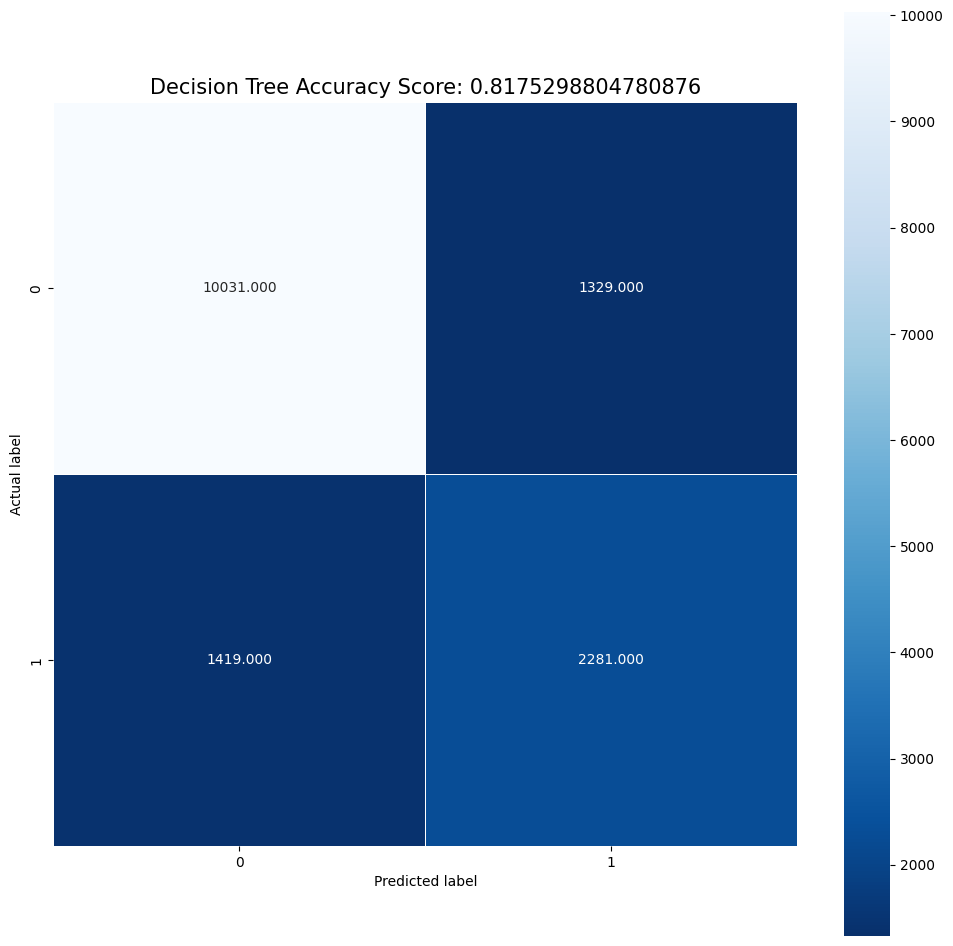

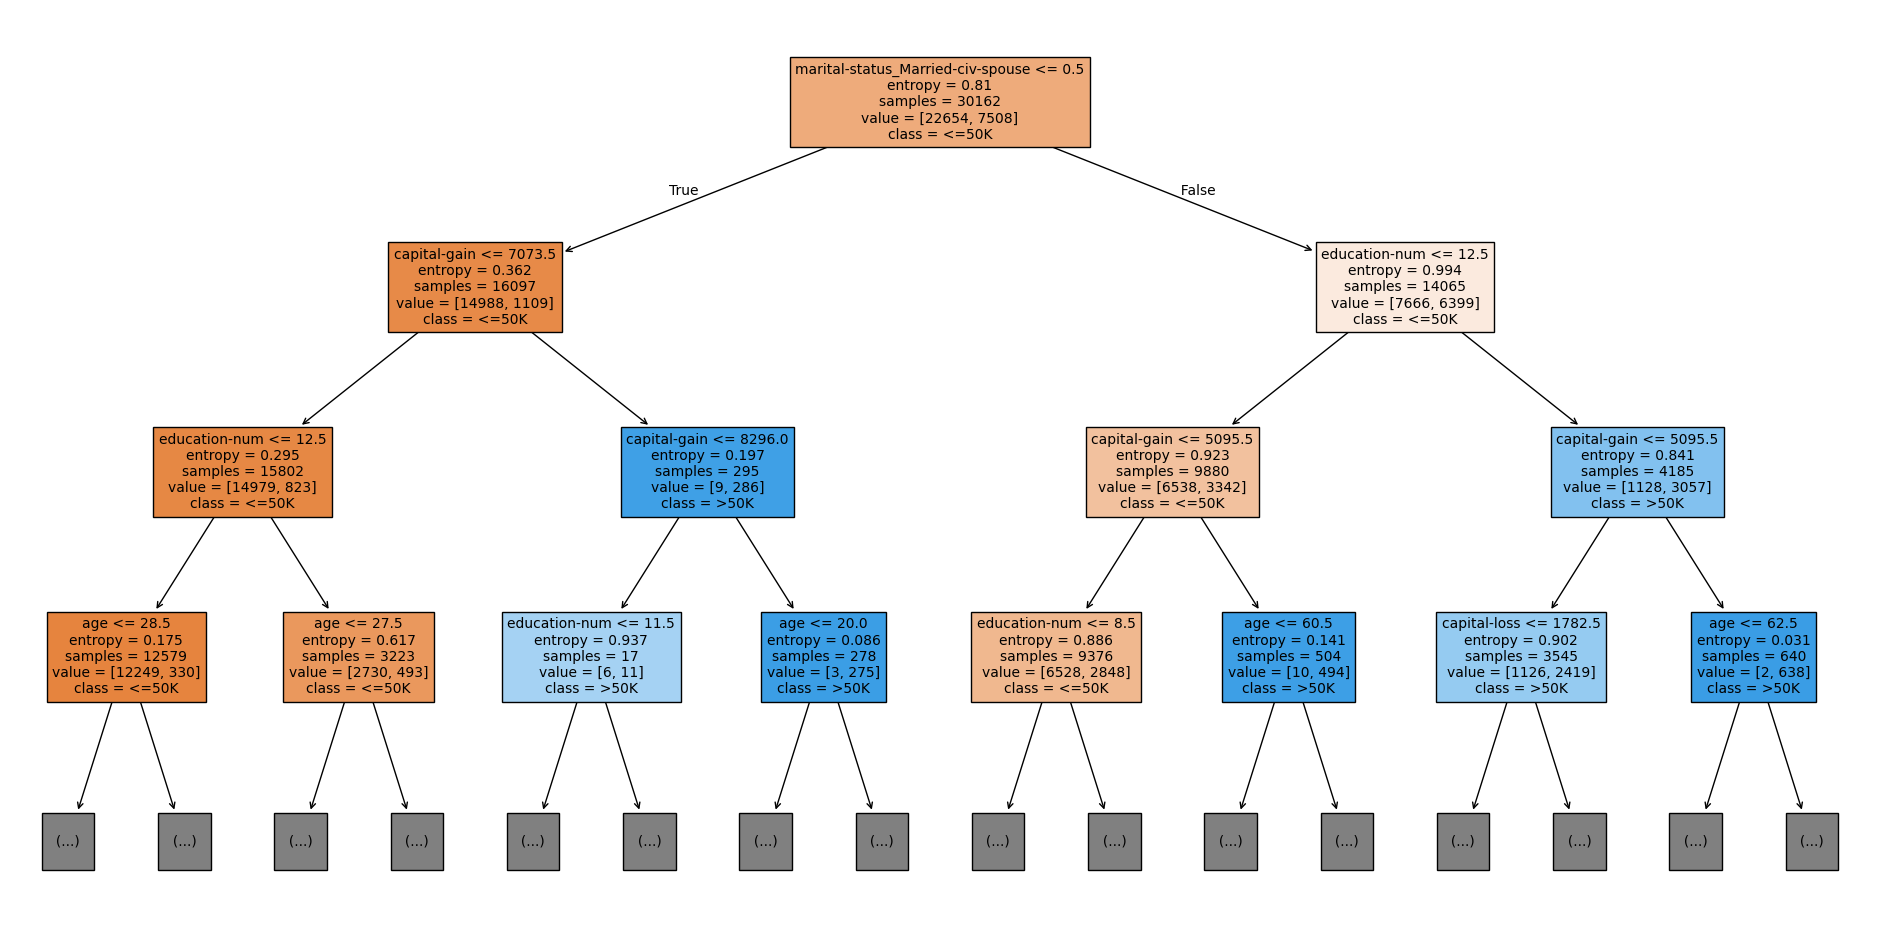

In [8]:
print_student_info("CÂU 7: XÂY DỰNG CÂY ID3")

# Xây dựng mô hình Decision Tree với criterion='entropy'
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
# Train Decision Tree Classifier
clf.fit(X_train, y_train)

# Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred))

# Tính toán ma trận nhầm lẫn và biểu diễn lên đồ thị heatmap
tree_cm = metrics.confusion_matrix(y_test, tree_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size=15)
plt.show()

# Biểu diễn cây ID3 (giới hạn max_depth để hiển thị trực quan rõ ràng)
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf, max_depth=3, feature_names=list(features_onehot.columns), class_names=np.unique(y_train), filled=True, fontsize=10)
plt.savefig('decision_tree.png', dpi=100)
plt.show()

## Câu 8: Lặp lại yêu cầu 7 đối với cây CART (criterion='gini')

=== CÂU 8: XÂY DỰNG CÂY CART ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.8122841965471448
Report:               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



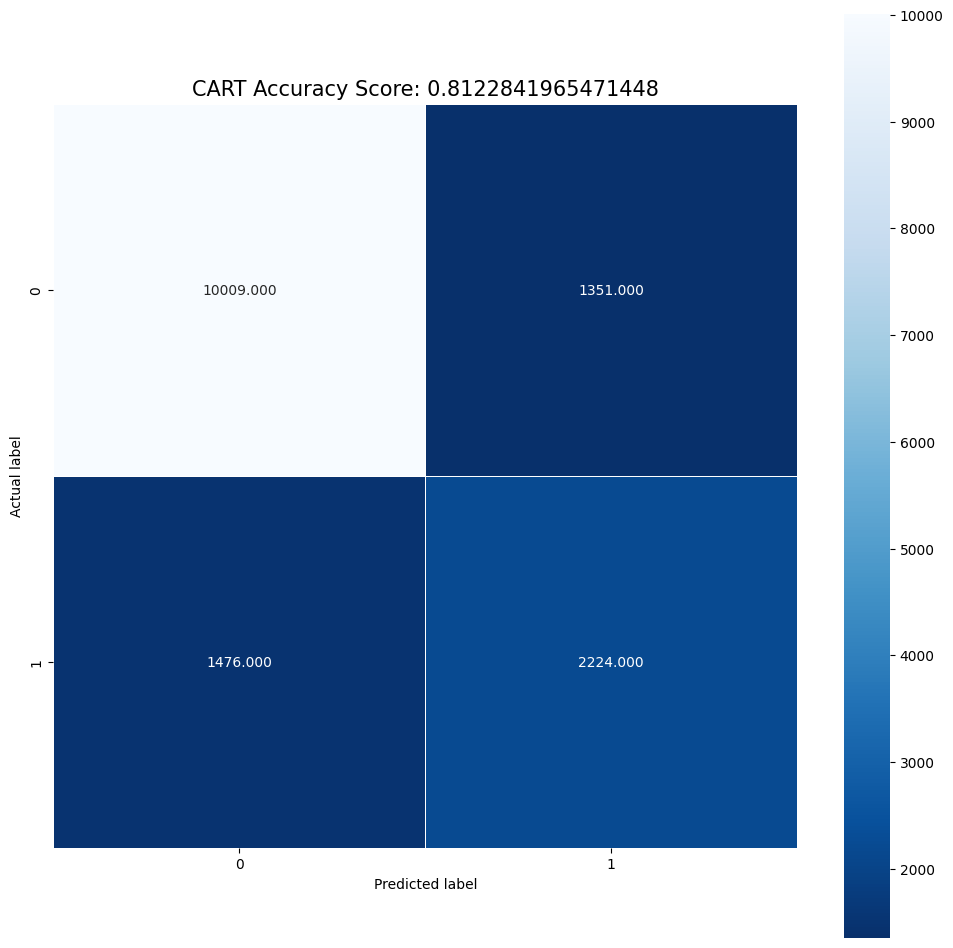

In [9]:
print_student_info("CÂU 8: XÂY DỰNG CÂY CART")

# Xây dựng mô hình với criterion='gini'
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred))

# Vẽ ma trận nhầm lẫn CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = 'CART Accuracy Score: {0}'.format(cart_score)
plt.title(title, size=15)
plt.show()

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes

=== CÂU 9: MÔ HÌNH NAÏVE BAYES ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

Accuracy: 0.8029216467463479
Report:               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



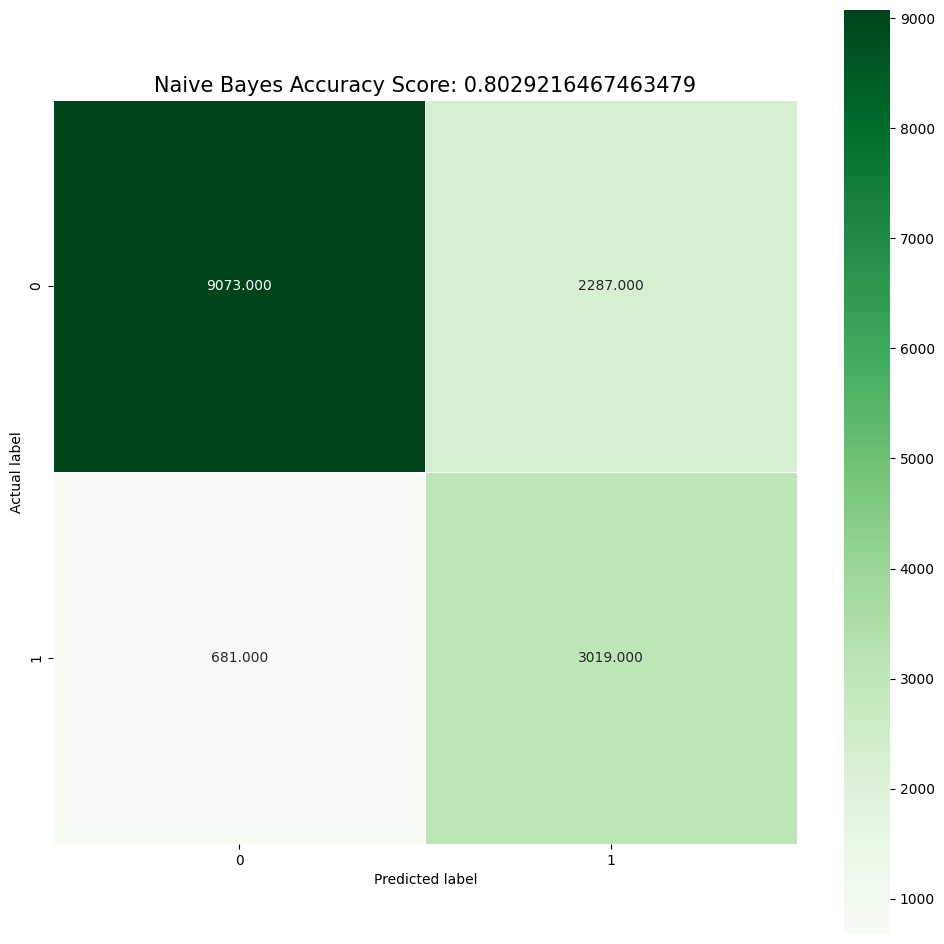

In [10]:
print_student_info("CÂU 9: MÔ HÌNH NAÏVE BAYES")

# Khởi tạo và huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

# Tính toán các giá trị đánh giá
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred))

# Biểu diễn ma trận nhầm lẫn bằng đồ thị heatmap (cmap='Greens')
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size=15)
plt.show()

## Câu 10: So sánh kết quả của các mô hình trên

In [11]:
print_student_info("CÂU 10: SO SÁNH CÁC MÔ HÌNH")

summary_df = pd.DataFrame({
    'Thuật toán': ['ID3 (Decision Tree - Entropy)', 'CART (Decision Tree - Gini)', 'Naïve Bayes (GaussianNB)'],
    'Độ chính xác (Accuracy)': [tree_score, cart_score, bayes_score]
})

print(summary_df.to_string(index=False))
print("\n--- NHẬN XÉT SO SÁNH ---")
print("1. Cây quyết định ID3 đạt độ chính xác ~ 81.75% (trên tập test 15.060 mẫu).")
print("2. Cây quyết định CART đạt độ chính xác tương đương ID3, xấp xỉ ~ 81.5% - 81.8%.")
print("3. Mô hình Naïve Bayes đạt độ chính xác ~ 80.29%, tuy thấp hơn cây quyết định một chút nhưng có tốc độ huấn luyện nhanh và dự đoán lớp <=50K rất tốt (Recall 80%, Precision 93%).")

=== CÂU 10: SO SÁNH CÁC MÔ HÌNH ===
Họ và tên: Nguyễn Anh Nguyên | MSSV: 6451071053

                   Thuật toán  Độ chính xác (Accuracy)
ID3 (Decision Tree - Entropy)                 0.817530
  CART (Decision Tree - Gini)                 0.812284
     Naïve Bayes (GaussianNB)                 0.802922

--- NHẬN XÉT SO SÁNH ---
1. Cây quyết định ID3 đạt độ chính xác ~ 81.75% (trên tập test 15.060 mẫu).
2. Cây quyết định CART đạt độ chính xác tương đương ID3, xấp xỉ ~ 81.5% - 81.8%.
3. Mô hình Naïve Bayes đạt độ chính xác ~ 80.29%, tuy thấp hơn cây quyết định một chút nhưng có tốc độ huấn luyện nhanh và dự đoán lớp <=50K rất tốt (Recall 80%, Precision 93%).
